# The held-out draw: the surrogate's error through onnxruntime, the quantised graph, and the autoencoder against the envelope gate

**Question:** On an independent Latin-hypercube draw of operating points, how accurate is each of the surrogate's ten outputs, what does 8-bit quantisation cost, and what share of planted off-manifold points does the autoencoder detect beside the envelope gate?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- draw the held-out operating points, with the same sampler and seed as the product's evaluation, and say why they are independent of the training draw;
- score the surrogate on them through onnxruntime, output by output, with R squared and the mean absolute percentage error;
- measure what the 8-bit graph loses against the float32 one, and check that P80 never falls as the setting opens;
- score the autoencoder on held-out and on planted off-manifold points, and set its detection against the envelope gate's.

## Setup

The same four libraries as notebook 01: numpy, matplotlib, onnxruntime and jsonschema.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

The imports add the sweep sampler and the product's own evaluation functions, which live in the pipeline's evaluation stage and are public: the R squared and MAPE function, the monotonicity check and the planting rule, with the function that gives the training targets of a result.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.model import sweep
from pipeline.model.bundles import load_bundle, session_for, decode_outputs, reconstruction_score
from pipeline.model.crusher import evaluate
from pipeline.model.crusher.encoding import encode_input, ae_feats
from pipeline.stages.evaluate import r2_mape, monotonicity_check, planted_points
from pipeline.stages.train import target_vector
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Data

The two released models. The surrogate and the autoencoder are released ChancaDEM models, trained by the product's own pipeline on a Latin-hypercube sweep of the engine and committed with their contracts (`surrogate-model`, `anomaly-model`). Licence class: MIT, as the rest of the repository; the training data is synthetic, drawn from the engine. Files read: the surrogate's contract and graphs (`data/derived/models/surrogate.json`, `surrogate.onnx`, `surrogate.int8.onnx`) and the autoencoder's (`data/derived/models/psd-ae.json`, `psd-ae.onnx`). The held-out metrics that the pipeline's evaluation stage records are checked by the test suite, and this notebook computes them again.

The cell loads both bundles and opens one onnxruntime session per graph.

In [2]:
# Load the two validated bundles and open a session for each graph
models_dir = ROOT / "data" / "derived" / "models"
sbundle = load_bundle("surrogate-model", models_dir)
abundle = load_bundle("anomaly-model", models_dir)
s32 = session_for(models_dir, sbundle["graphs"]["float32"])
s8 = session_for(models_dir, sbundle["graphs"]["int8"])
sa = session_for(models_dir, abundle["graph"])
trained = sbundle["training"]
print("trained on", trained["n_train"], "points; the contract records a held-out draw of", trained["n_test"])

trained on 6430 points; the contract records a held-out draw of 2196


## Method

**Step 1, the held-out draw.** The training points come from a Latin-hypercube sweep of the engine with seed 12345, 1400 points per machine. The evaluation draws a second, independent sweep with seed 67890 and 480 points per machine, not a split of the first, so no held-out point was seen in training. The sampler stratifies each of the six continuous inputs in its own machine's range (a gyratory never runs a 6 mm setting), and the pipeline drops the degenerate draws, those the engine marks invalid or with a reduction ratio under 1.02. The cell draws and labels the points with the engine and counts the machines.

In [3]:
# Draw the held-out points with the product's sampler and seed, label them with the engine and count them
drawn = sweep.draw(480, 67890)
held = sweep.label(drawn)
print("drawn:", len(drawn), "| kept after dropping degenerate points:", len(held))
print("dropped:", len(drawn) - len(held))
print({m: sum(r.op.machine == m for r in held) for m in sweep.MACHINES})

drawn: 2400 | kept after dropping degenerate points: 2196
dropped: 204
{'cone-sec': 468, 'cone-tert': 479, 'jaw': 479, 'cone-short-head': 480, 'gyratory': 290}


**Step 2, the score per output.** The cell encodes the held-out points with the shared encoder, runs the float32 graph on all of them in one batch, decodes the outputs and compares each with the engine's value, which is the teacher's label. The product's evaluation function computes, per output, the R squared and the mean absolute percentage error in original units (the size outputs are decoded from logarithms before comparing).

In [4]:
# Score the float32 graph on the held-out points, output by output
x = np.array([encode_input(r.op, sbundle["in_mean"], sbundle["in_std"]) for r in held], np.float32)
z32, z8 = s32.run(None, {"x": x})[0], s8.run(None, {"x": x})[0]
predicted32, predicted8 = decode_outputs(z32, sbundle), decode_outputs(z8, sbundle)
raw = np.array([target_vector(r) for r in held])
truth = raw.copy()
log = np.array(sbundle["out_log"], dtype=bool)
truth[:, log] = np.power(10.0, raw[:, log])
score = {}
for j, name in enumerate(sbundle["output_order"]):
    score[name] = (r2_mape(predicted32[:, j], truth[:, j]), r2_mape(predicted8[:, j], truth[:, j]))
    (r2, mape), (_, mape8) = score[name]
    print(f"{name:15s} R2 {r2:.4f}  MAPE {mape:6.2f} %  int8 MAPE {mape8:6.2f} %")

p80_mm          R2 0.9970  MAPE   4.06 %  int8 MAPE   4.57 %
p50_mm          R2 0.9947  MAPE   5.73 %  int8 MAPE   6.13 %
p20_mm          R2 0.9886  MAPE   9.21 %  int8 MAPE   9.48 %
pass_1          R2 0.9868  MAPE   8.11 %  int8 MAPE   8.33 %
pass_4          R2 0.9884  MAPE   7.70 %  int8 MAPE   7.91 %
pass_8          R2 0.9930  MAPE   5.30 %  int8 MAPE   5.64 %
pass_16         R2 0.9936  MAPE   5.29 %  int8 MAPE   5.54 %
pass_32         R2 0.9971  MAPE   2.73 %  int8 MAPE   2.87 %
throughput_tph  R2 0.9984  MAPE   5.02 %  int8 MAPE   5.43 %
power_kw        R2 0.9792  MAPE   6.47 %  int8 MAPE   6.43 %


The figure draws the surrogate's P80 against the engine's for all held-out points, on logarithmic axes since P80 runs over nearly two decades, 3 to 200 mm, across the five machines. A perfect emulator lies on the diagonal.

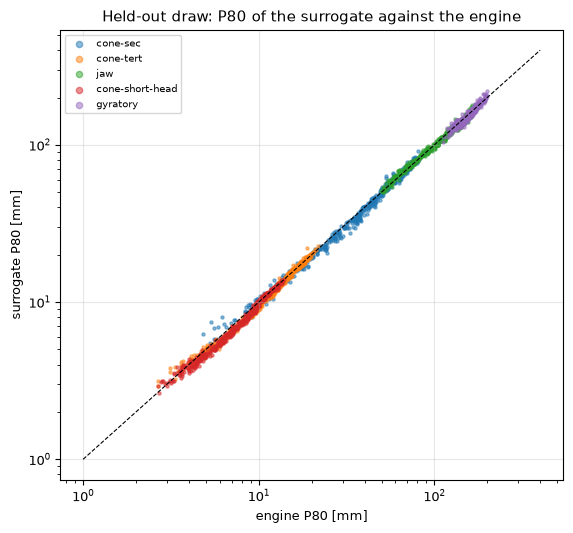

In [5]:
# Parity plot of the surrogate's P80 against the engine's on the held-out draw, coloured by machine
fig, ax = plt.subplots(figsize=(5.8, 5.4))
machine = np.array([r.op.machine for r in held])
for m in sweep.MACHINES:
    pick = machine == m
    ax.scatter(truth[pick, 0], predicted32[pick, 0], s=5, alpha=0.5, label=m)
ax.plot([1, 400], [1, 400], "k--", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("engine P80 [mm]")
ax.set_ylabel("surrogate P80 [mm]")
ax.set_title("Held-out draw: P80 of the surrogate against the engine")
ax.legend(fontsize=7, markerscale=2)
fig.tight_layout()
plt.show()

The cloud hugs the diagonal over the whole range, with the visible scatter at the fine end, the short-head cone's products under 5 mm, where a small number of millimetres is a large relative error; the gyratory's coarse products, the least sampled machine with 290 of its 480 draws surviving the degenerate filter against 468 to 480 for the others, lie on a tight line. The R squared of P80 is 0.997 and the MAPE 4.06 percent; the worst output by MAPE is `p20_mm`, at 9.2 percent, the fine tail of the product, which is the steepest part of the size distribution. The figure shows the typical error, not the tail of errors; the worst single point can be much farther from the line than the cloud suggests.

**Step 3, the cost of 8 bits.** The released contract carries a second graph, quantised dynamically to 8-bit integers, half the size, for the live web lane. The cell compares the two graphs: the largest absolute difference of the standardised outputs on the whole held-out draw, and the mean MAPE over the ten outputs of each graph, and the figure sets the two MAPE values per output side by side.

largest absolute difference of standardised outputs, float32 against int8: 0.2349
mean MAPE, float32 and int8: 5.963 6.233


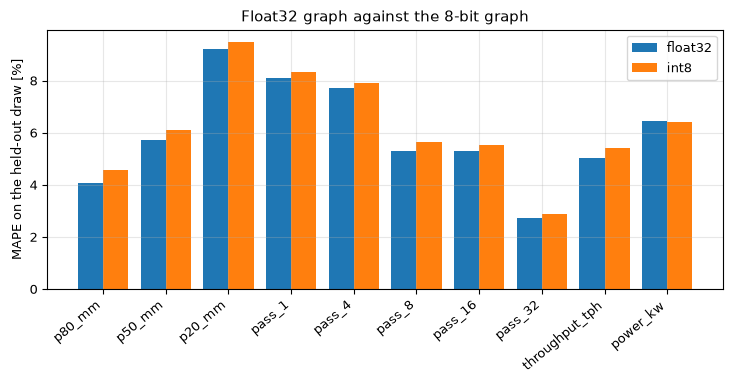

In [6]:
# Largest standardised difference between the two graphs, mean MAPE of each, and the per-output bars
names = list(score)
mape32 = [score[k][0][1] for k in names]
mape8 = [score[k][1][1] for k in names]
largest = float(np.max(np.abs(z32.astype(np.float64) - z8)))
print("largest absolute difference of standardised outputs, float32 against int8:", round(largest, 4))
print("mean MAPE, float32 and int8:", round(float(np.mean(mape32)), 3), round(float(np.mean(mape8)), 3))
fig, ax = plt.subplots()
ax.bar(np.arange(10) - 0.2, mape32, 0.4, label="float32")
ax.bar(np.arange(10) + 0.2, mape8, 0.4, label="int8")
ax.set_xticks(range(10), names, rotation=40, ha="right")
ax.set_ylabel("MAPE on the held-out draw [%]")
ax.set_title("Float32 graph against the 8-bit graph")
ax.legend()
fig.tight_layout()
plt.show()

The two bars are nearly the same height for every output, within about half a point: the quantised graph is half the bytes for almost the same accuracy. The standardised outputs differ by up to 0.23 for some single point, which is why the product reports the worst case as well as the mean. Power is the one output where int8 is not worse, 6.43 against 6.47 percent, a reminder that quantisation noise can fall either way. The figure shows only accuracy against the engine, not speed, which is a property of the runtime and the machine.

**Step 4, monotonicity.** A physical property that the product holds the network to: P80 must not fall by more than 0.001 mm as the closed-side setting opens, at three base points of the other inputs, on every machine. The pipeline's check builds 16 settings across each machine's range at the 25th, 50th and 75th percentiles of the other five inputs, 15 curves in all, and runs them through the float32 graph.

In [7]:
# Run the pipeline's monotonicity check of P80 against the setting on the float32 graph
monotone, curves = monotonicity_check(sbundle, s32)
print("P80 monotone in the setting:", monotone, "| curves checked:", curves)

P80 monotone in the setting: True | curves checked: 15


**Step 5, the autoencoder.** The second released model is a denoising autoencoder, 14-16-6-16-14, trained on the 14-feature signature of the engine's results (the logarithms of P80, P50, P20 and F80, the five passing fractions, throughput, power, the reduction ratio, the specific energy and the feed uniformity). Its reconstruction error is an anomaly score: a result far from the training manifold reconstructs badly. The alarm threshold is the 99th percentile of the training scores, 0.24454, so by construction about 1 percent of in-distribution points alarm. The cell scores the held-out results and reports the false-alarm rate, and the share of the held-out points that the envelope gate flags.

In [8]:
# Score the held-out results with the autoencoder; the false-alarm rate beside the envelope gate's flag rate
threshold = abundle["threshold_p99"]
held_scores = np.array([reconstruction_score(ae_feats(r), abundle, sa) for r in held])
false_alarm = float(np.mean(~np.isfinite(held_scores) | (held_scores > threshold)))
gate_alarm = float(np.mean([r.out_of_envelope for r in held]))
print("threshold:", threshold, "| autoencoder false-alarm rate:", round(false_alarm * 100, 1), "%")
print("envelope gate flags:", round(gate_alarm * 100, 1), "% of the held-out points")

threshold: 0.24454 | autoencoder false-alarm rate: 1.0 %
envelope gate flags: 0.0 % of the held-out points


**Step 6, planted off-manifold points.** A detector must also be shown a case it should catch. The product's rule plants, for each held-out point, one outside its machine's training range: one of the six continuous inputs moved above its upper bound by half the range width, or below its lower bound to half of it, or two neighbouring inputs moved in opposite senses, cycling over 18 patterns. The engine then labels each planted point, so its signature is an honest engine result at an input the network never saw. The cell scores the planted points with both detectors and draws the score distributions.

planted points: 2196 | autoencoder detection: 28.0 %
envelope gate detection: 13.9 %
flagged by both: 178 | autoencoder only: 436 | gate only: 127 | neither: 1455
median score, held-out and planted: 0.0338 0.1112


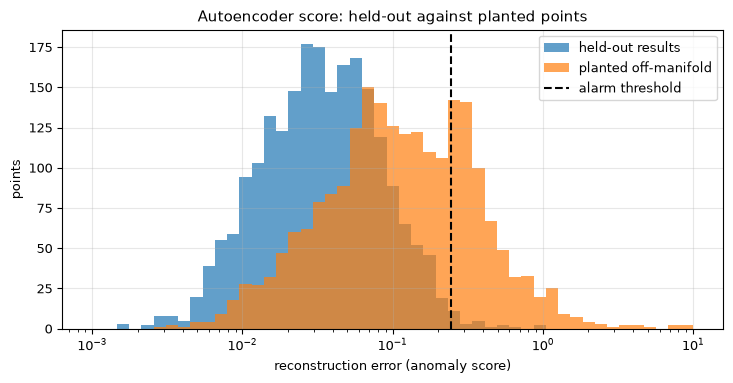

In [9]:
# Plant off-manifold points, label them with the engine, score them with the autoencoder and the envelope gate, and count the overlap
planted = [evaluate(o) for o in planted_points(held)]
planted = [r for r in planted if all(np.isfinite(ae_feats(r)))]
planted_scores = np.array([reconstruction_score(ae_feats(r), abundle, sa) for r in planted])
flagged = ~np.isfinite(planted_scores) | (planted_scores > threshold)
detection = float(np.mean(flagged))
gated = np.array([r.out_of_envelope for r in planted])
gate_detection = float(np.mean(gated))
print("planted points:", len(planted), "| autoencoder detection:", round(detection * 100, 1), "%")
print("envelope gate detection:", round(gate_detection * 100, 1), "%")
print("flagged by both:", int((flagged & gated).sum()), "| autoencoder only:", int((flagged & ~gated).sum()),
      "| gate only:", int((~flagged & gated).sum()), "| neither:", int((~flagged & ~gated).sum()))
medians = np.median(held_scores), np.median(planted_scores)
print("median score, held-out and planted:", round(float(medians[0]), 4), round(float(medians[1]), 4))
fig, ax = plt.subplots()
bins = np.logspace(-3, 1, 50)
ax.hist(held_scores, bins=bins, alpha=0.7, label="held-out results")
ax.hist(planted_scores, bins=bins, alpha=0.7, label="planted off-manifold")
ax.axvline(threshold, color="k", ls="--", label="alarm threshold")
ax.set_xscale("log")
ax.set_xlabel("reconstruction error (anomaly score)")
ax.set_ylabel("points")
ax.set_title("Autoencoder score: held-out against planted points")
ax.legend()
fig.tight_layout()
plt.show()

The planted points are shifted to the right, with a median score of 0.111 against 0.034 for the held-out results, but the two histograms overlap heavily and only the right tail of the planted ones crosses the threshold. The autoencoder detects 28.0 percent of the planted points against the 13.9 percent that the envelope gate flags, so it adds a signal the gate does not have, and still misses seven in ten. The overlap printed above shows that the two signals differ: 178 planted points are flagged by both, 436 by the autoencoder only, 127 by the gate only and 1455 by neither. The reason is visible in the construction: the detector looks at the signature of the engine's result, and an input moved out of range can give a perfectly ordinary result, since the engine saturates (the t10 cap, for instance). The figure shows the detector is informative and not sufficient; it should not be read as a guarantee that a point without an alarm is inside the domain.

## Results

**Answer:** on the held-out draw of 2196 operating points (2400 drawn, 204 degenerate dropped), the surrogate reproduces the engine with R squared between 0.979 (power) and 0.998 (throughput) and a MAPE between 2.73 percent (`pass_32`) and 9.21 percent (`p20_mm`), P80 at R squared 0.997 and 4.06 percent. The 8-bit graph costs at most about half a point of MAPE per output for half the bytes. P80 is monotone in the setting on all 15 curves. The autoencoder alarms on 1.0 percent of held-out points by construction and detects 28.0 percent of the planted off-manifold points, against 13.9 percent for the envelope gate, which flags none of the held-out points.

The first figure shows accuracy across machines, the third the weakness of the detector. A validator would conclude that the surrogate is accurate against its teacher, the engine, to about 5 percent on average and monotone where the physics demands it, and that the autoencoder is a partial guard: useful, complementary to the gate (127 planted points are flagged by the gate alone and 436 by the autoencoder alone), and silent on seven in ten planted points. Neither measurement involves a plant: both compare a network with the engine that trained it. Notebook 03 sets the surrogate against the measured surveys.

## Summary

A learned model is only as good as the question it is held to. Against its teacher on an independent draw, the surrogate is accurate and monotone and its quantised graph is nearly free; the autoencoder detects some of the planted anomalies and the gate others. The measurements share a limit, that they compare the network with the engine. Notebook 03 asks the question that decides whether a surrogate is useful for the plant: what it says about the ten surveys.

## References

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193